# Weather and Air Pollution in Delhi: How Much Does Weather Explain PM2.5?

**IT462 Exploratory Data Analysis · Weather and pollution analysis**

**Author:** Aarohi Mehta · 202401002

## Objective
Describe how Delhi's weather and PM2.5 behave together between March and August 2025, and measure how much of the hourly variation in PM2.5 weather and NO2 can explain once the season and time of day are accounted for.

1. What do the weather and PM2.5 series look like (data quality, distributions, daily cycles)?
2. Which weather variables go with high PM2.5, and does the link survive after removing the season and the hour of day?
3. Does weather *lead* PM2.5 by a few hours (lag correlations, Granger tests)?
4. How much of PM2.5 do weather and NO2 explain together (regression with calendar controls)?
5. Does weather change how strongly NO2 shows up in PM2.5 (stagnation, shallow boundary layer)?

## Data
OpenAQ hourly PM2.5 and NO2 from one station, and Open-Meteo hourly weather for the station's coordinates: temperature, relative humidity, wind speed and direction, precipitation, surface pressure and boundary-layer height (BLH). Files are read from `data/raw/`.

**Coverage limit.** The weather file ends on **31 Aug 2025**, so every result here uses 1 Mar – 31 Aug (4,416 hours). October and November, the most polluted months, have no weather data in this analysis; the findings do not carry over to them.

## Methods
Data checks and descriptive statistics; Spearman correlations on raw series and on month-hour anomalies; binned medians and an event study for rain; lagged correlations and Granger tests on gap-free blocks; OLS on ln PM2.5 with month and hour fixed effects and Newey-West (HAC) standard errors; NO2 slopes within weather terciles.

## Conventions
`random_state=42`; every plot is titled and labelled; "association" is used instead of "cause" unless a result supports more.


## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
print(sorted(p.name for p in RAW.rglob("*.csv")))

['firms_noaa20_2025_mar_nov.csv', 'no2_hourly_mar_nov.csv', 'pm25_hourly_mar_nov.csv', 'weather_hourly.csv']


## 1. Load, clean and check the data
PM2.5 and NO2 are reindexed to a full hourly calendar so gaps become visible; zero NO2 readings (3) are set missing; gaps of at most 6 hours are interpolated for modelling, and the untouched `pm25_obs` is kept for descriptive statistics. The weather file is already hourly.

In [2]:
def read_aq(name):
    d = pd.read_csv(RAW / "air_quality" / f"{name}_hourly_mar_nov.csv"); d["t"] = pd.to_datetime(d["datetime_from_local"].str[:19])
    return d.drop_duplicates("t").set_index("t")["value"]
HOURS = pd.date_range("2025-03-01 05:00", "2025-12-01 04:00", freq="h")
pm_obs, no2_obs = read_aq("pm25").reindex(HOURS), read_aq("no2").reindex(HOURS).pipe(lambda s: s.mask(s == 0))
pm, no2 = (s.interpolate("time", limit=6, limit_area="inside") for s in (pm_obs, no2_obs))
w = pd.read_csv(RAW / "weather" / "weather_hourly.csv", parse_dates=["datetime_local"]).set_index("datetime_local")
print("weather:", w.shape, "|", w.index.min(), "->", w.index.max(), "| duplicated timestamps:", int(w.index.duplicated().sum()), "| missing cells:", int(w.isna().sum().sum()))
print("hours expected Mar 1 - Aug 31:", len(pd.date_range("2025-03-01", "2025-08-31 23:00", freq="h")), "| rows in file:", len(w))
H = pd.DataFrame({"pm25_obs": pm_obs, "pm25": pm, "no2": no2}).join(w, how="inner")
print("hours in the weather window:", len(H), "| with PM2.5 observed:", int(H.pm25_obs.notna().sum()), f"({H.pm25_obs.notna().mean():.0%})", "| NO2 observed:", int(no2_obs.reindex(H.index).notna().sum()))
rng = pd.DataFrame({"min": w.min(), "max": w.max(), "mean": w.mean(), "median": w.median(), "std": w.std()}).round(1); print(rng)

weather: (4416, 7) | 2025-03-01 00:00:00 -> 2025-08-31 23:00:00 | duplicated timestamps: 0 | missing cells: 0
hours expected Mar 1 - Aug 31: 4416 | rows in file: 4416
hours in the weather window: 4411 | with PM2.5 observed: 3883 (88%) | NO2 observed: 3944
                         min     max   mean  median    std
temperature_2m          12.5    43.1   29.2    28.8    5.0
relative_humidity_2m     5.0    99.0   58.1    62.0   26.2
wind_speed_10m           0.0     8.6    2.2     2.0    1.1
wind_direction_10m       3.0   360.0  172.7   142.0   90.9
precipitation            0.0    11.1    0.1     0.0    0.6
surface_pressure       966.0   991.5  976.9   976.1    4.8
boundary_layer_height   10.0  5220.0  641.0   305.0  814.9


> **Observation:** The weather file is complete for 1 Mar – 31 Aug: 4,416 hourly rows, no duplicate timestamps and no missing cells. PM2.5 is observed in 3,883 of the 4,411 hours that lie on the pollution calendar (88%) and NO2 in 3,944, so the number of usable hours is set by gaps in the pollution data, not by the weather. Weather stops on 31 Aug while pollution continues to 30 Nov, so September–November cannot be analysed.

In [3]:
# Outlier check: Tukey IQR fences, count of hours outside; physical plausibility
q1, q3 = w.quantile(.25), w.quantile(.75); iqr = q3 - q1; out = ((w < q1 - 1.5 * iqr) | (w > q3 + 1.5 * iqr)).sum()
print(pd.DataFrame({"outside 1.5*IQR": out, "% of hours": (out / len(w) * 100).round(1), "skewness": w.skew().round(2)}))
print("hours with zero wind speed:", int((w.wind_speed_10m == 0).sum()), "| hours with RH = 100:", int((w.relative_humidity_2m >= 100).sum()), "| rain hours:", int((w.precipitation > 0).sum()), "| hours with >= 1 mm:", int((w.precipitation >= 1).sum()))
print("BLH lowest 5 values:", w.boundary_layer_height.nsmallest(5).round(0).tolist(), "| highest:", w.boundary_layer_height.nlargest(3).round(0).tolist())

                       outside 1.5*IQR  % of hours  skewness
temperature_2m                     179         4.1     -0.04
relative_humidity_2m                 0         0.0     -0.25
wind_speed_10m                      63         1.4      0.69
wind_direction_10m                   0         0.0      0.33
precipitation                      617        14.0      8.80
surface_pressure                     3         0.1      0.46
boundary_layer_height              383         8.7      2.27
hours with zero wind speed: 0 | hours with RH = 100: 0 | rain hours: 617 | hours with >= 1 mm: 144
BLH lowest 5 values: [10.0, 10.0, 10.0, 10.0, 10.0] | highest: [5220.0, 5220.0, 5180.0]


> **Observation:** Nothing is removed. Precipitation is extremely skewed (skewness 8.8) and 14% of hours fall outside the IQR fences, but that only reflects that most hours are dry; 144 hours have at least 1 mm and these are real rain. BLH (skewness 2.3, 8.7% outside the fences) reaches 5,220 m on hot pre-monsoon afternoons, which is high but plausible, and its five lowest values are all exactly 10 m, which looks like a floor in the model output rather than a measurement. Temperature spans 12.5–43.1 °C, and there are no hours with zero wind or 100% humidity. Wind speed and BLH are used on a log scale because of their skew.

## 2. Describing the weather

     temp    rh  wind  pressure  blh_median  rain_mm  pm25  pm25_median
Mar  23.9  42.6   2.5     984.2       245.0      5.8  49.4         42.3
Apr  30.8  28.5   2.2     979.8       257.5     18.7  63.9         61.0
May  31.4  49.3   2.3     976.0       380.0     30.7  63.9         55.6
Jun  31.4  62.6   2.0     973.3       310.0    129.8  43.8         41.3
Jul  29.1  81.2   1.8     972.4       315.0    155.3  22.9         21.5
Aug  28.5  83.4   2.0     975.7       325.0    198.9  20.0         19.5


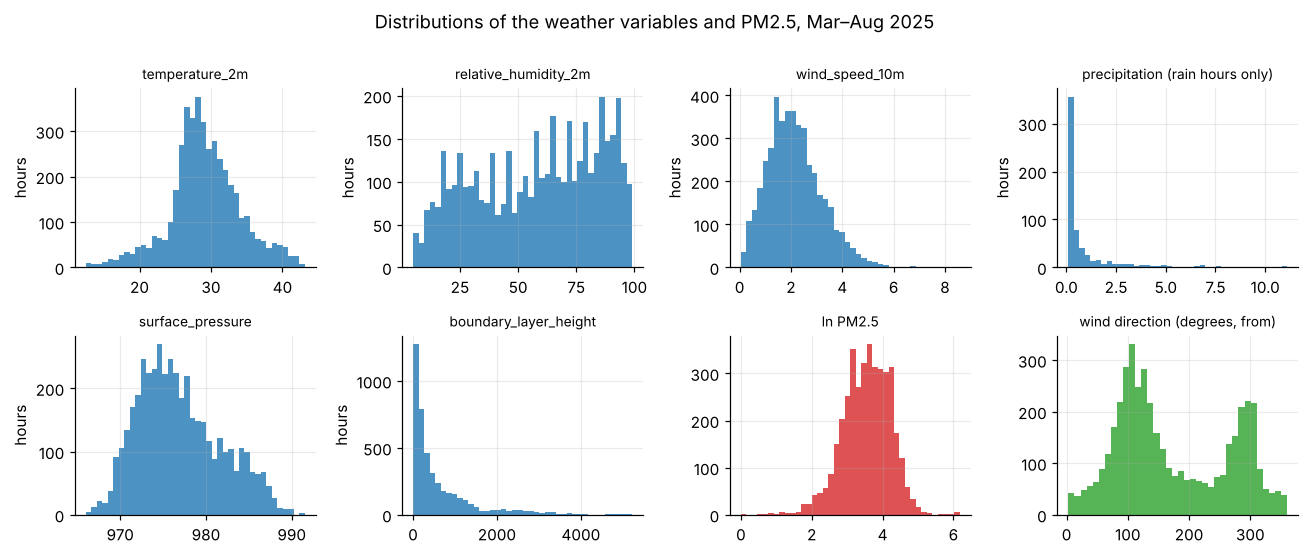

In [4]:
mon = H.groupby(H.index.month).agg(temp=("temperature_2m", "mean"), rh=("relative_humidity_2m", "mean"), wind=("wind_speed_10m", "mean"), pressure=("surface_pressure", "mean"),
                                    blh_median=("boundary_layer_height", "median"), rain_mm=("precipitation", "sum"), pm25=("pm25_obs", "mean"), pm25_median=("pm25_obs", "median"))
mon.index = ["Mar", "Apr", "May", "Jun", "Jul", "Aug"]; print(mon.round(1))
fig, ax = plt.subplots(2, 4, figsize=(12, 5)); cols = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "precipitation", "surface_pressure", "boundary_layer_height"]
for a, c in zip(ax.ravel(), cols):
    a.hist(w[c] if c != "precipitation" else w[c][w[c] > 0], bins=40, color="tab:blue", alpha=.8); a.set_title(c + (" (rain hours only)" if c == "precipitation" else ""), fontsize=9); a.set_ylabel("hours")
a = ax.ravel()[6]; a.hist(np.log(H.pm25_obs.dropna()), bins=40, color="tab:red", alpha=.8); a.set_title("ln PM2.5", fontsize=9)
a = ax.ravel()[7]; a.hist(w.wind_direction_10m, bins=36, color="tab:green", alpha=.8); a.set_title("wind direction (degrees, from)", fontsize=9)
plt.suptitle("Distributions of the weather variables and PM2.5, Mar–Aug 2025", y=1.0); plt.tight_layout(); plt.show()

> **Observation:** The months differ sharply. April–May are hot and dry (mean humidity 28.5% in April) and have the highest PM2.5 (mean 63.9 µg/m³ in both), while July–August are humid (81–83%), wet (155 and 199 mm of rain, summed over hours) and clean (22.9 and 20.0 µg/m³). Mean surface pressure falls from 984 hPa in March to 972 hPa in July. Wind speed hardly changes (1.8–2.5 m/s). Humidity, rain and pressure therefore move with the season, and so does PM2.5, which is why raw correlations need the season removed.

## 3. Daily cycles
Weather and pollution both follow the clock. Plotting the median by hour of day shows what a model must remove before looking for weather effects.

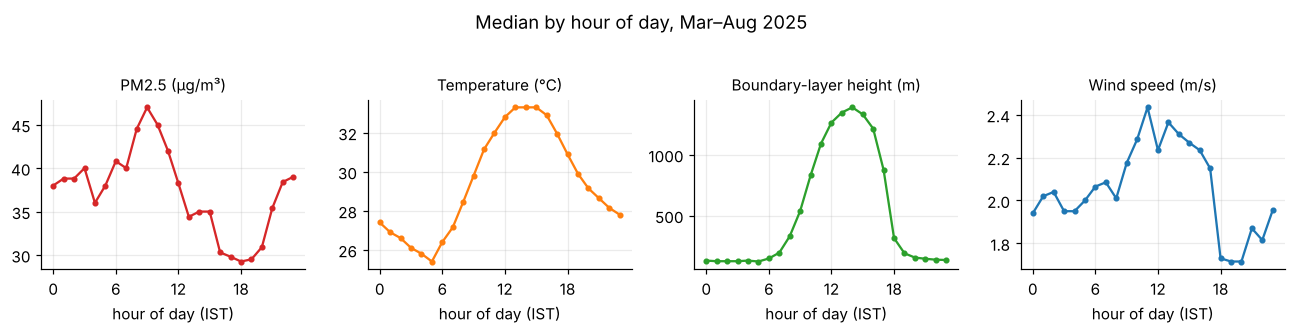

PM2.5 median: min 29.2 at 18:00, max 47.0 at 09:00
BLH median: min 122 m at 05:00, max 1390 m at 14:00
temperature_2m median: min 25.4 at 05:00, max 33.3 at 13:00
wind_speed_10m median: min 1.7 at 19:00, max 2.4 at 11:00
correlation between hourly median PM2.5 and BLH across the 24 hours: -0.13


In [5]:
g = H.groupby(H.index.hour)
fig, ax = plt.subplots(1, 4, figsize=(12, 2.9))
for a, (s, ttl, c) in zip(ax, [(g.pm25_obs.median(), "PM2.5 (µg/m³)", "tab:red"), (g.temperature_2m.median(), "Temperature (°C)", "tab:orange"),
                               (g.boundary_layer_height.median(), "Boundary-layer height (m)", "tab:green"), (g.wind_speed_10m.median(), "Wind speed (m/s)", "tab:blue")]):
    a.plot(s.index, s.values, color=c, marker="o", ms=3); a.set_title(ttl, fontsize=10); a.set_xlabel("hour of day (IST)"); a.set_xticks(range(0, 24, 6))
plt.suptitle("Median by hour of day, Mar–Aug 2025", y=1.03); plt.tight_layout(); plt.show()
dm = g.pm25_obs.median(); print("PM2.5 median: min %.1f at %02d:00, max %.1f at %02d:00" % (dm.min(), dm.idxmin(), dm.max(), dm.idxmax()))
bl = g.boundary_layer_height.median(); print("BLH median: min %.0f m at %02d:00, max %.0f m at %02d:00" % (bl.min(), bl.idxmin(), bl.max(), bl.idxmax()))
for c in ("temperature_2m", "wind_speed_10m"):
    m_ = g[c].median(); print(f"{c} median: min {m_.min():.1f} at {m_.idxmin():02d}:00, max {m_.max():.1f} at {m_.idxmax():02d}:00")
print("correlation between hourly median PM2.5 and BLH across the 24 hours:", round(dm.corr(bl), 2))

> **Observation:** PM2.5 peaks at 09:00 (median 47.0 µg/m³) and is lowest at 18:00 (29.2). The boundary layer is shallowest at 05:00 (122 m) and deepest at 14:00 (1,390 m), so each PM2.5 extreme arrives about four hours after the matching BLH extreme. That delay is why the correlation between the 24 hourly medians of PM2.5 and BLH is only −0.13 even though the two curves are clearly linked, and it anticipates the lag of about three hours found for BLH in section 5. Temperature and wind follow the usual daytime pattern (temperature 25.4 to 33.3 °C). Because the clock matters this much, the later analysis removes the typical value for each month and hour.

## 4. Which weather variables go with PM2.5?
**Raw** correlations mix three things: real short-term effects, the *season* (the monsoon is humid, rainy and clean) and the *time of day*. To isolate the short-term part, we also compute correlations on **month-hour anomalies** (each series minus its average for that month and hour of day).

                 raw ρ  anomaly ρ
NO2 (ln)          0.40       0.20
Temperature       0.11       0.32
Rel. humidity    -0.56      -0.24
Wind speed (ln)  -0.00      -0.13
Wind u (E–W)      0.08       0.05
Wind v (N–S)     -0.01       0.03
Precipitation    -0.36      -0.14
Pressure          0.33      -0.02
BL height (ln)   -0.10      -0.10


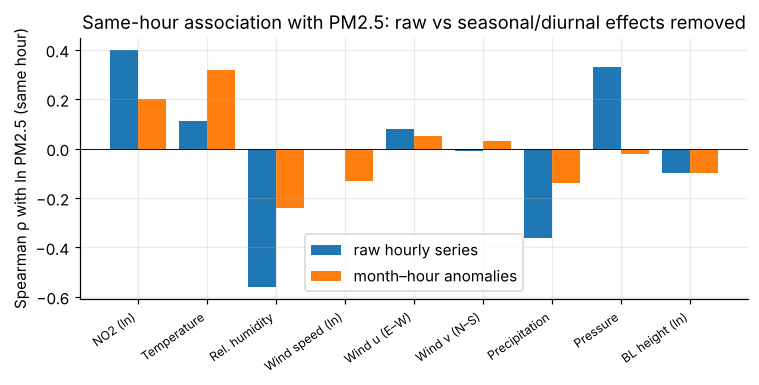

In [6]:
W = H.copy(); W["lnpm"] = np.log(W.pm25); W["lnno2"] = np.log(W.no2); W["lnws"] = np.log(W.wind_speed_10m + .1); W["lnblh"] = np.log(W.boundary_layer_height)
th = np.radians(W.wind_direction_10m); W["u"] = -W.wind_speed_10m * np.sin(th); W["v"] = -W.wind_speed_10m * np.cos(th)
VARS = {"lnno2": "NO2 (ln)", "temperature_2m": "Temperature", "relative_humidity_2m": "Rel. humidity", "lnws": "Wind speed (ln)", "u": "Wind u (E–W)", "v": "Wind v (N–S)",
        "precipitation": "Precipitation", "surface_pressure": "Pressure", "lnblh": "BL height (ln)"}
anom = lambda s: s - s.groupby([s.index.month, s.index.hour]).transform("mean")
A = pd.DataFrame({k: anom(W[k]) for k in ["lnpm"] + list(VARS)})
rho_raw = pd.Series({VARS[k]: stats.spearmanr(W[["lnpm", k]].dropna().lnpm, W[["lnpm", k]].dropna()[k])[0] for k in VARS})
rho_an  = pd.Series({VARS[k]: stats.spearmanr(A[["lnpm", k]].dropna().lnpm, A[["lnpm", k]].dropna()[k])[0] for k in VARS})
T = pd.DataFrame({"raw ρ": rho_raw, "anomaly ρ": rho_an}).round(2); print(T)
fig, ax = plt.subplots(figsize=(7, 3.6)); x = np.arange(len(T)); ax.bar(x - .2, T["raw ρ"], .4, label="raw hourly series", color="tab:blue"); ax.bar(x + .2, T["anomaly ρ"], .4, label="month–hour anomalies", color="tab:orange")
ax.set_xticks(x); ax.set_xticklabels(T.index, rotation=35, ha="right", fontsize=8); ax.axhline(0, color="k", lw=.6); ax.set_ylabel("Spearman ρ with ln PM2.5 (same hour)")
ax.set_title("Same-hour association with PM2.5: raw vs seasonal/diurnal effects removed"); ax.legend(); plt.tight_layout(); plt.show()

> **Observation:** Raw correlations are dominated by the season: humidity (−0.56), precipitation (−0.36), pressure (+0.33) and NO2 (+0.40). Once each series is compared with its usual value for that month and hour, pressure drops to −0.02 and the humidity and rain correlations roughly halve (−0.24 and −0.14), so much of their raw strength was seasonal. Temperature moves the other way, from +0.11 to +0.32: temperature stays similar from April to August while PM2.5 falls with the monsoon, which hid a positive link between warmer-than-usual hours and higher PM2.5. Wind speed (−0.13) and BLH (−0.10) become slightly negative and NO2 falls to +0.20. No single variable has a correlation above about 0.3 once the calendar is removed.

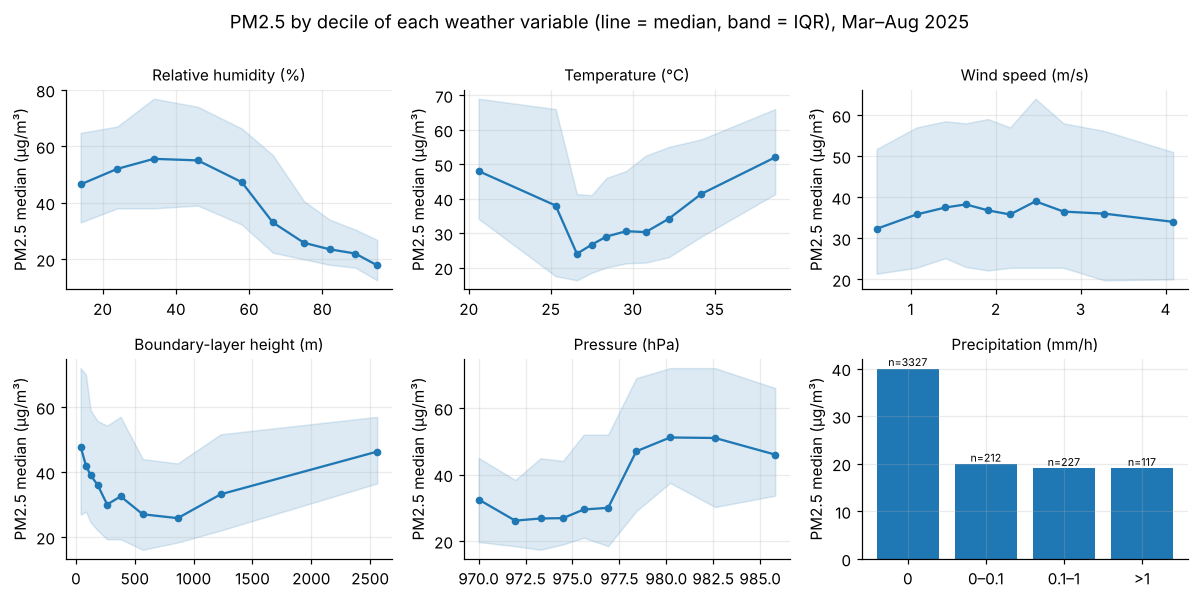

median PM2.5 for RH <40 / 40-70 / >70: [np.float64(50.9), np.float64(46.2), np.float64(22.8)]
median PM2.5 by temperature_2m tercile (low/mid/high): [36.0, 29.3, 42.8] | tercile edges: [27.3, 31.0]
median PM2.5 by wind_speed_10m tercile (low/mid/high): [35.0, 37.6, 36.0] | tercile edges: [1.6, 2.5]
median PM2.5 by boundary_layer_height tercile (low/mid/high): [41.3, 30.6, 36.0] | tercile edges: [170.0, 605.0]
median PM2.5 by surface_pressure tercile (low/mid/high): [27.8, 31.0, 50.0] | tercile edges: [974.2, 978.6]


In [7]:
# Binned medians: PM2.5 in each decile of the weather variable
fig, ax = plt.subplots(2, 3, figsize=(11, 5.4))
for a, (c, ttl) in zip(ax.ravel(), [("relative_humidity_2m", "Relative humidity (%)"), ("temperature_2m", "Temperature (°C)"), ("wind_speed_10m", "Wind speed (m/s)"),
                                    ("boundary_layer_height", "Boundary-layer height (m)"), ("surface_pressure", "Pressure (hPa)"), ("precipitation", "Precipitation (mm/h)")]):
    d = H[[c, "pm25_obs"]].dropna()
    if c == "precipitation":
        d["b"] = pd.cut(d[c], [-.001, 0, .1, 1, 100], labels=["0", "0–0.1", "0.1–1", ">1"]); gm = d.groupby("b").pm25_obs.agg(["median", "count"]); a.bar(range(len(gm)), gm["median"], color="tab:blue"); a.set_xticks(range(len(gm))); a.set_xticklabels(gm.index)
        for i, n in enumerate(gm["count"]): a.text(i, gm["median"].iloc[i], f"n={n}", ha="center", va="bottom", fontsize=7)
    else:
        d["b"] = pd.qcut(d[c], 10, duplicates="drop"); gm = d.groupby("b").agg(x=(c, "median"), y=("pm25_obs", "median"), q1=("pm25_obs", lambda s: s.quantile(.25)), q3=("pm25_obs", lambda s: s.quantile(.75)))
        a.fill_between(gm.x, gm.q1, gm.q3, color="tab:blue", alpha=.15); a.plot(gm.x, gm.y, "o-", color="tab:blue", ms=4)
    a.set_title(ttl, fontsize=10); a.set_ylabel("PM2.5 median (µg/m³)")
plt.suptitle("PM2.5 by decile of each weather variable (line = median, band = IQR), Mar–Aug 2025", y=1.0); plt.tight_layout(); plt.show()
rh = H[["relative_humidity_2m", "pm25_obs"]].dropna(); print("median PM2.5 for RH <40 / 40-70 / >70:", [round(rh[m].pm25_obs.median(), 1) for m in (rh.relative_humidity_2m < 40, rh.relative_humidity_2m.between(40, 70), rh.relative_humidity_2m > 70)])
for c in ("temperature_2m", "wind_speed_10m", "boundary_layer_height", "surface_pressure"):
    d_ = H[[c, "pm25_obs"]].dropna(); t_ = pd.qcut(d_[c], 3, labels=["low", "mid", "high"]); print(f"median PM2.5 by {c} tercile (low/mid/high):", d_.groupby(t_).pm25_obs.median().round(1).tolist(), "| tercile edges:", d_[c].quantile([1/3, 2/3]).round(1).tolist())


> **Observation:** Median PM2.5 is clearly lower when relative humidity exceeds 70% (22.8 µg/m³, against 50.9 below 40% and 46.2 in between) and clearly higher in the top pressure tercile (50.0, against 27.8 and 31.0). Both are seasonal markers, so they should not be read as effects. The other variables show little or an uneven pattern: temperature terciles give 36.0, 29.3 and 42.8, wind speed 35.0, 37.6 and 36.0, and BLH 41.3, 30.6 and 36.0. Raw binned medians therefore support only the humidity and pressure story, which the anomaly analysis shows is mostly season.

### 4.1 Wind direction
Direction is the compass bearing the wind blows *from*. For each of eight sectors we compare PM2.5 on calm (below the median speed) and breezy hours, since direction matters less when the air is still.

        hours  median_pm25  mean_ws
sector                             
N         141         42.0      1.7
NE        276         37.0      1.7
E         938         30.0      2.3
SE        870         36.2      2.1
S         317         38.0      1.6
SW        251         32.0      1.6
W         594         38.8      2.3
NW        496         38.0      2.9


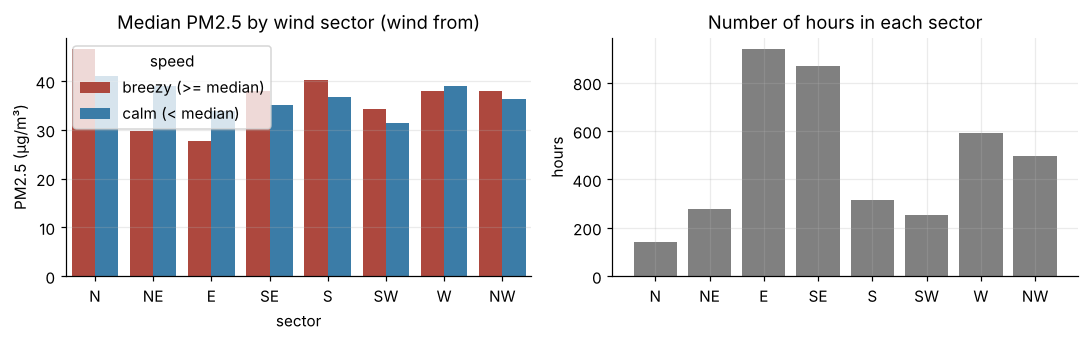

median PM2.5, calm vs breezy hours: {'breezy (>= median)': 36.0, 'calm (< median)': 36.0} | median speed split at 2.04 m/s
share of hours with wind from the west/north-west/north-east (W+NW+NE): 35%


In [8]:
H2 = H.dropna(subset=["pm25_obs"]).copy(); H2["sector"] = pd.cut((H2.wind_direction_10m + 22.5) % 360, np.arange(0, 361, 45), labels=["N", "NE", "E", "SE", "S", "SW", "W", "NW"], right=False)
H2["speed"] = np.where(H2.wind_speed_10m < H2.wind_speed_10m.median(), "calm (< median)", "breezy (>= median)")
tab = H2.groupby("sector").agg(hours=("pm25_obs", "size"), median_pm25=("pm25_obs", "median"), mean_ws=("wind_speed_10m", "mean")).round(1); print(tab)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2)); sns.barplot(data=H2, x="sector", y="pm25_obs", hue="speed", estimator=np.median, errorbar=None, ax=ax[0], palette=["#c0392b", "#2980b9"]); ax[0].set_title("Median PM2.5 by wind sector (wind from)"); ax[0].set_ylabel("PM2.5 (µg/m³)")
ax[1].bar(tab.index.astype(str), tab.hours, color="grey"); ax[1].set_title("Number of hours in each sector"); ax[1].set_ylabel("hours"); plt.tight_layout(); plt.show()
print("median PM2.5, calm vs breezy hours:", H2.groupby("speed").pm25_obs.median().round(1).to_dict(), "| median speed split at", round(H2.wind_speed_10m.median(), 2), "m/s")
print("share of hours with wind from the west/north-west/north-east (W+NW+NE): %.0f%%" % (tab.loc[["W", "NW", "NE"], "hours"].sum() / tab.hours.sum() * 100))

> **Observation:** Calm and breezy hours have the same median PM2.5 (36.0 µg/m³, split at 2.04 m/s). Medians by wind sector run from 30.0 (E) to 42.0 (N), but the northern sector has only 141 hours while E and SE have 938 and 870, and the gaps of a few µg/m³ do not form a clear pattern. Only 35% of hours have wind from the W, NW or NE. Winds here are weak overall (mean 2.2 m/s), and there is no evidence in this single-station data for a dominant transport direction.

### 4.2 Rain
Does rain clean the air? Two views: (i) hours with and without rain, and (ii) an **event study** around the *onset* of rain (≥ 1 mm in an hour after at least two dry hours): PM2.5 divided by its mean over the six hours before onset, median and inter-quartile range across events.

median PM2.5: dry hours 40.0 (n=3327), hours with >=1 mm 18.5 (n=125)


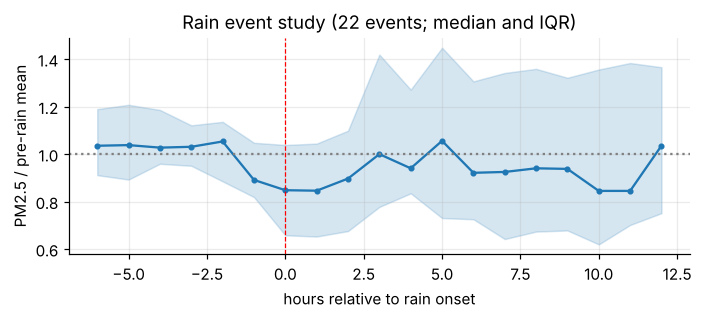

rain onsets: 33 | used: 22
median ratio at onset hour: 0.85 | hours +1..+6: [0.85 0.9  1.   0.94 1.06 0.92] | +12 h: 1.04


In [9]:
dry = H[H.precipitation == 0].pm25_obs.dropna(); wet = H[H.precipitation >= 1].pm25_obs.dropna()
print(f"median PM2.5: dry hours {dry.median():.1f} (n={len(dry)}), hours with >=1 mm {wet.median():.1f} (n={len(wet)})")
rain = (H.precipitation >= 1) & (H.precipitation.shift(1).fillna(0) < .1) & (H.precipitation.shift(2).fillna(0) < .1); prof = []
for t0 in H.index[rain]:
    seg = H.pm25_obs.reindex(pd.date_range(t0 - pd.Timedelta(hours=6), t0 + pd.Timedelta(hours=12), freq="h")); base = seg.iloc[:7].mean()
    if seg.notna().sum() >= 15 and base > 0: prof.append(seg.values / base)
prof = np.array(prof); xs = np.arange(-6, 13); med, lo, hi = np.nanmedian(prof, 0), np.nanpercentile(prof, 25, 0), np.nanpercentile(prof, 75, 0)
fig, ax = plt.subplots(figsize=(6.5, 3)); ax.fill_between(xs, lo, hi, alpha=.18, color="tab:blue"); ax.plot(xs, med, "o-", ms=3, color="tab:blue"); ax.axhline(1, color="grey", ls=":"); ax.axvline(0, color="red", ls="--", lw=.8)
ax.set_xlabel("hours relative to rain onset"); ax.set_ylabel("PM2.5 / pre-rain mean"); ax.set_title(f"Rain event study ({len(prof)} events; median and IQR)"); plt.tight_layout(); plt.show()
print("rain onsets:", int(rain.sum()), "| used:", len(prof)); print("median ratio at onset hour:", round(med[6], 2), "| hours +1..+6:", np.round(med[7:13], 2), "| +12 h:", round(med[-1], 2))

> **Observation:** PM2.5 is much lower in hours with at least 1 mm of rain (median 18.5 µg/m³, n = 125) than in dry hours (40.0, n = 3,327), but that comparison is mostly monsoon versus non-monsoon. The event study is the fairer test: of 33 rain onsets, 22 had enough PM2.5 data. PM2.5 is already 15% below its pre-rain mean in the onset hour (ratio 0.85), sits at 0.85–0.90 for the next two hours, and is back near 1.0 by +3 h (0.94–1.06 afterwards, 1.04 at +12 h). Rain is therefore followed by a small, short-lived dip of about 10–15%, estimated from only 22 events.

## 5. Does weather *lead* PM2.5? Lags and autocorrelation
For each variable *X* we correlate PM2.5 at time *t* with *X* at *t−k* for k = 0…6 hours, on the anomaly series (so the season and the clock are not doing the work).

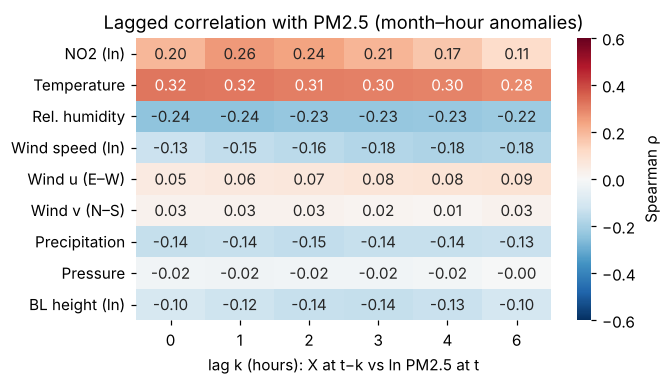

strongest lag for each variable: {'NO2 (ln)': (1, np.float64(0.26)), 'Temperature': (0, np.float64(0.32)), 'Rel. humidity': (0, np.float64(-0.24)), 'Wind speed (ln)': (4, np.float64(-0.18)), 'Wind u (E–W)': (6, np.float64(0.09)), 'Wind v (N–S)': (0, np.float64(0.03)), 'Precipitation': (2, np.float64(-0.15)), 'Pressure': (1, np.float64(-0.02)), 'BL height (ln)': (3, np.float64(-0.14))}
autocorrelation of ln PM2.5 anomaly at 1, 3, 6, 12, 24 h: [np.float64(0.89), np.float64(0.64), np.float64(0.41), np.float64(0.22), np.float64(0.17)]


In [10]:
LAGS = [0, 1, 2, 3, 4, 6]
an = pd.DataFrame({VARS[k]: [A.lnpm.corr(A[k].shift(L), method="spearman") for L in LAGS] for k in VARS}, index=LAGS).T
fig, ax = plt.subplots(figsize=(6.2, 3.6)); sns.heatmap(an, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, ax=ax, cbar_kws={"label": "Spearman ρ"}); ax.set_xlabel("lag k (hours): X at t−k vs ln PM2.5 at t"); ax.grid(False)
ax.set_title("Lagged correlation with PM2.5 (month–hour anomalies)"); plt.tight_layout(); plt.show()
best = an.abs().idxmax(axis=1); print("strongest lag for each variable:", {k: (int(best[k]), round(an.loc[k, best[k]], 2)) for k in an.index})
print("autocorrelation of ln PM2.5 anomaly at 1, 3, 6, 12, 24 h:", [round(A.lnpm.corr(A.lnpm.shift(L)), 2) for L in (1, 3, 6, 12, 24)])

> **Observation:** On the anomaly series, temperature (ρ = 0.32) and humidity (−0.24) correlate most strongly at lag 0, NO2 at lag 1 (0.26), precipitation at lag 2 (−0.15), BLH at lag 3 (−0.14) and wind speed at lag 4 (−0.18). Pressure and the wind components stay close to zero at all lags. Since weather is itself autocorrelated, the correlation changes only a little from one lag to the next, so the exact peak lag should be treated as approximate. PM2.5 is very persistent: the autocorrelation of its anomaly is 0.89 at 1 h, 0.64 at 3 h, 0.41 at 6 h, 0.22 at 12 h and 0.17 at 24 h.

### 5.1 Granger tests
A variable *X* **Granger-causes** PM2.5 if the past of *X* improves a prediction of PM2.5 *beyond* PM2.5's own past. This is about **predictive precedence**, not physical causation. We fit regressions with 6 hourly lags of PM2.5 only (restricted) and with 6 lags of PM2.5 plus 6 lags of *X* (unrestricted), pool the data over gap-free blocks (at least 48 hours) so lags never cross a gap, and compare with an F-test. The reverse direction (PM2.5 → X) is also tested. With nine variables the Bonferroni 5% level is p < 0.0056.

gap-free blocks: 16 | hours in them: 3943 | longest: 665


                 F (X→PM)  p (X→PM)  ΔR² (%)  p (PM→X) Bonferroni sig. X→PM
NO2 (ln)          43.1133    0.0000   1.2692    0.0325                  yes
BL height (ln)     5.9243    0.0000   0.1843    0.2939                  yes
Wind speed (ln)    4.4834    0.0002   0.1398    0.0551                  yes
Pressure           3.7003    0.0011   0.1155    0.0437                  yes
Temperature        3.5645    0.0016   0.1113    0.0006                  yes
Rel. humidity      2.7589    0.0112   0.0863    0.4912                   no
Precipitation      2.7236    0.0122   0.0852    0.0000                   no
Wind u (E–W)       2.0461    0.0563   0.0640    0.1822                   no
Wind v (N–S)       0.2248    0.9689   0.0071    0.4056                   no


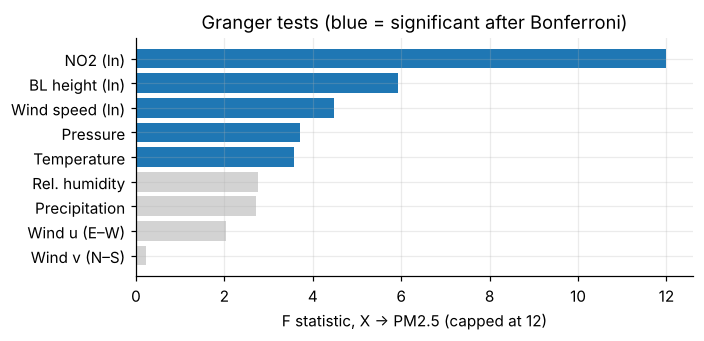

In [11]:
def blocks(df, cols, minlen):
    ok = df[cols].notna().all(axis=1).values; res, i = [], 0
    while i < len(ok):
        if ok[i]:
            j = i
            while j < len(ok) and ok[j]: j += 1
            if j - i >= minlen: res.append((i, j))
            i = j
        else: i += 1
    return res
def granger_pooled(df, y, x, p, minlen=48):
    ys, rr, uu = [], [], []
    for i, j in blocks(df, [y, x], minlen):
        b = df[[y, x]].iloc[i:j]; Y, X = b[y].values, b[x].values
        for t in range(p, len(b)): yl, xl = Y[t-p:t][::-1], X[t-p:t][::-1]; ys.append(Y[t]); rr.append(yl); uu.append(np.r_[yl, xl])
    ys = np.array(ys); mr = sm.OLS(ys, sm.add_constant(np.array(rr))).fit(); mu = sm.OLS(ys, sm.add_constant(np.array(uu))).fit(); f, pv, _ = mu.compare_f_test(mr)
    return dict(F=f, p=pv, n=len(ys), dR2=mu.rsquared - mr.rsquared)
blk = blocks(A, ["lnpm"] + list(VARS), 48); print("gap-free blocks:", len(blk), "| hours in them:", sum(j - i for i, j in blk), "| longest:", max(j - i for i, j in blk))
G = pd.DataFrame({VARS[k]: {"F (X→PM)": (g := granger_pooled(A, "lnpm", k, 6))["F"], "p (X→PM)": g["p"], "ΔR² (%)": g["dR2"] * 100, "p (PM→X)": granger_pooled(A, k, "lnpm", 6)["p"]} for k in VARS}).T
G["Bonferroni sig. X→PM"] = np.where(G["p (X→PM)"] < .05 / len(VARS), "yes", "no"); print(G.round(4).sort_values("F (X→PM)", ascending=False).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.2)); s = G["F (X→PM)"].sort_values(); ax.barh(s.index, s.clip(upper=12), color=["tab:blue" if G.loc[i, "Bonferroni sig. X→PM"] == "yes" else "lightgrey" for i in s.index]); ax.set_xlabel("F statistic, X → PM2.5 (capped at 12)")
ax.set_title("Granger tests (blue = significant after Bonferroni)"); plt.tight_layout(); plt.show()

> **Observation:** Using 16 gap-free blocks (3,943 hours, longest 665), NO2 has the strongest predictive link (F = 43.1, +1.27% of variance). After a Bonferroni correction for nine tests, BLH (F = 5.9), wind speed, pressure and temperature also add information; humidity (p = 0.011), precipitation (p = 0.012) and the wind components do not. The gains are tiny, 0.1–0.2% of variance for each weather variable, because PM2.5's own recent past already explains most of its next value. The reverse direction is also significant for precipitation and temperature (p < 0.001), so these tests show predictive precedence in time, which can come from shared seasonal and daily structure, and not cause and effect.

## 6. How much do weather and NO2 explain together? (regression with calendar controls)
Model: ln PM2.5 at *t* on predictors at *t−1* (the previous hour, to avoid using simultaneous information), with **hour-of-day and month fixed effects** so the daily cycle and seasonal level are removed. Consecutive hours are strongly dependent, so standard errors are **Newey–West (HAC, 24 lags)**. Coefficients are converted to % change in PM2.5 for a one-standard-deviation increase in the predictor.

rows: 4052
calendar only      0.500
+ NO2              0.525
+ weather          0.564
+ NO2 + weather    0.579
Name: R², dtype: float64
                         % per SD      lo      hi      p
lnno2_l1                   12.177   3.813  21.214  0.004
temperature_2m_l1          13.850   6.376  21.849  0.000
relative_humidity_2m_l1    -6.564 -15.072   2.795  0.163
lnws_l1                    -0.486  -4.082   3.245  0.795
surface_pressure_l1        -1.360  -8.139   5.920  0.706
lnblh_l1                  -15.985 -20.717 -10.971  0.000
wet_l1                     -7.768 -10.782  -4.653  0.000


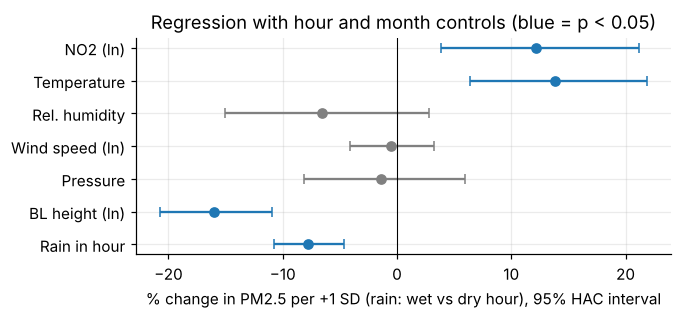

In [12]:
Z = W.copy(); base = ["lnno2", "temperature_2m", "relative_humidity_2m", "lnws", "surface_pressure", "lnblh"]
for k in base: Z[k + "_l1"] = Z[k].shift(1)
Z["wet_l1"] = (Z.precipitation.shift(1) > 0).astype(float); feat = [k + "_l1" for k in base] + ["wet_l1"]
Zd = Z[["lnpm"] + feat].dropna(); Zd["hour"], Zd["month"] = Zd.index.hour, Zd.index.month
cal = pd.get_dummies(Zd[["hour", "month"]].astype(str), drop_first=True, dtype=float)
def fit(cols): return sm.OLS(Zd.lnpm, sm.add_constant(pd.concat([Zd[cols], cal], axis=1))).fit(cov_type="HAC", cov_kwds=dict(maxlags=24))
m0 = sm.OLS(Zd.lnpm, sm.add_constant(cal)).fit(); m_no = fit(["lnno2_l1"]); m_w = fit([c for c in feat if c != "lnno2_l1"]); m_all = fit(feat)
print("rows:", len(Zd)); print(pd.Series({"calendar only": m0.rsquared, "+ NO2": m_no.rsquared, "+ weather": m_w.rsquared, "+ NO2 + weather": m_all.rsquared}).round(3).rename("R²"))
sd = Zd[feat].std(); co = pd.DataFrame({"b": m_all.params[feat], "se": m_all.bse[feat], "p": m_all.pvalues[feat]}); co["% per SD"] = (np.exp(co.b * sd) - 1) * 100
co["lo"] = (np.exp((co.b - 1.96 * co.se) * sd) - 1) * 100; co["hi"] = (np.exp((co.b + 1.96 * co.se) * sd) - 1) * 100; print(co[["% per SD", "lo", "hi", "p"]].round(3))
names = {"lnno2_l1": "NO2 (ln)", "temperature_2m_l1": "Temperature", "relative_humidity_2m_l1": "Rel. humidity", "lnws_l1": "Wind speed (ln)", "surface_pressure_l1": "Pressure", "lnblh_l1": "BL height (ln)", "wet_l1": "Rain in hour"}
fig, ax = plt.subplots(figsize=(6.3, 3)); yy = np.arange(len(feat))[::-1]
for yi, k in zip(yy, feat): ax.errorbar(co.loc[k, "% per SD"], yi, xerr=[[co.loc[k, "% per SD"] - co.loc[k, "lo"]], [co.loc[k, "hi"] - co.loc[k, "% per SD"]]], fmt="o", color="tab:blue" if co.loc[k, "p"] < .05 else "grey", capsize=3)
ax.axvline(0, color="k", lw=.7); ax.set_yticks(yy); ax.set_yticklabels([names[k] for k in feat]); ax.set_xlabel("% change in PM2.5 per +1 SD (rain: wet vs dry hour), 95% HAC interval"); ax.set_title("Regression with hour and month controls (blue = p < 0.05)"); plt.tight_layout(); plt.show()

> **Observation:** With month and hour effects only, R² is 0.500, so half of the variation in ln PM2.5 is calendar. Adding NO2 lifts it to 0.525, adding weather to 0.564 and both to 0.579, so weather adds about 6 percentage points and NO2 about 2.5. Per one-standard-deviation increase in the previous hour, PM2.5 is associated with: BLH −16.0% (95% interval −20.7 to −11.0), temperature +13.9% (6.4 to 21.8), NO2 +12.2% (3.8 to 21.2) and rain in the hour −7.8% (−10.8 to −4.7). Humidity (−6.6%), wind speed (−0.5%) and pressure (−1.4%) have intervals that include zero. The positive temperature coefficient should be read as an association that is entangled with BLH, since warm hours also have deep boundary layers.

In [13]:
# Do the controls matter? Same regression WITHOUT month/hour effects
X = sm.add_constant(Zd[feat]); m_nc = sm.OLS(Zd.lnpm, X).fit(cov_type="HAC", cov_kwds=dict(maxlags=24))
cmp = pd.DataFrame({"no controls": (np.exp(m_nc.params[feat] * sd) - 1) * 100, "with hour+month FE": co["% per SD"]}).round(1); cmp.index = [names[k] for k in cmp.index]
print(cmp); print("R² without controls: %.3f | with controls: %.3f" % (m_nc.rsquared, m_all.rsquared))

                 no controls  with hour+month FE
NO2 (ln)                11.6                12.2
Temperature              5.6                13.8
Rel. humidity          -26.9                -6.6
Wind speed (ln)          0.9                -0.5
Pressure                 2.3                -1.4
BL height (ln)         -16.5               -16.0
Rain in hour            -9.2                -7.8
R² without controls: 0.403 | with controls: 0.579


> **Observation:** Dropping the month and hour effects changes the conclusion for some variables and not for others. Humidity goes from −26.9% per SD without controls to −6.6% with them, and its interval then includes zero, so its apparent strength was mainly season. Temperature changes from +5.6% to +13.9%. BLH (−16.5% vs −16.0%), NO2 (+11.6% vs +12.2%) and rain (−9.2% vs −7.8%) barely move, so these are the associations that survive the calendar. R² rises from 0.403 to 0.579 with the controls.

## 7. Stagnation and the NO2 link
Cold, still, shallow air should trap emissions. We split hours into terciles of **boundary-layer height** and **wind speed** and look at the *anomaly* of ln PM2.5 (so the season/clock is already removed), shown as % above or below the usual PM2.5 for that month and hour.

% difference from the usual PM2.5 for that month and hour
 ws_t      low wind  mid wind  high wind
blh_t                                  
low BLH        7.9       8.6       -7.7
mid BLH       -5.2      -2.0      -10.2
high BLH       5.5       3.9       -5.1

hours per cell
 ws_t      low wind  mid wind  high wind
blh_t                                  
low BLH        792       469        103
mid BLH        262       528        565
high BLH       325       346        683


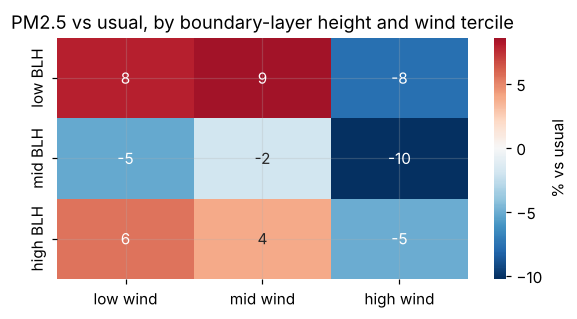

In [14]:
S = pd.DataFrame({"blh": W.boundary_layer_height, "ws": W.wind_speed_10m, "an": A.lnpm}).dropna()
S["blh_t"] = pd.qcut(S.blh, 3, labels=["low BLH", "mid BLH", "high BLH"]); S["ws_t"] = pd.qcut(S.ws, 3, labels=["low wind", "mid wind", "high wind"])
pv = (np.exp(S.groupby(["blh_t", "ws_t"]).an.mean().unstack()) - 1) * 100; nn = S.groupby(["blh_t", "ws_t"]).size().unstack()
print("% difference from the usual PM2.5 for that month and hour\n", pv.round(1)); print("\nhours per cell\n", nn)
fig, ax = plt.subplots(figsize=(5.4, 3)); sns.heatmap(pv, annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "% vs usual"}); ax.set_title("PM2.5 vs usual, by boundary-layer height and wind tercile"); ax.set_xlabel(""); ax.set_ylabel(""); plt.tight_layout(); plt.show()

> **Observation:** Measured against the usual PM2.5 for each month and hour, the stagnant cells (low BLH with low or mid wind) are only about 8% higher than normal (+7.9% and +8.6%). The strongest contrast is with wind: high-wind hours are 5–10% below normal at every BLH level. The BLH effect itself is not monotone in this table (the middle tercile is lowest in each wind column), unlike the regression where BLH is clearly negative. The table does not control for other variables while the regression does, and temperature and BLH are correlated, so the two views disagree for that reason. The low-BLH, high-wind cell has only 103 hours.

  moderator tercile  slope    lo   hi    n
  BL height     low   0.30  0.15 0.45 1354
  BL height     mid   0.12 -0.03 0.28 1354
  BL height    high   0.11 -0.02 0.24 1344
 Wind speed     low   0.16  0.02 0.29 1368
 Wind speed     mid   0.13 -0.01 0.27 1337
 Wind speed    high   0.25  0.10 0.40 1347
   Humidity     low   0.48  0.39 0.58 1360
   Humidity     mid   0.15 -0.01 0.32 1400
   Humidity    high  -0.02 -0.13 0.10 1292
Temperature     low   0.32  0.13 0.50 1355
Temperature     mid   0.10 -0.07 0.27 1351
Temperature    high   0.13  0.02 0.24 1346


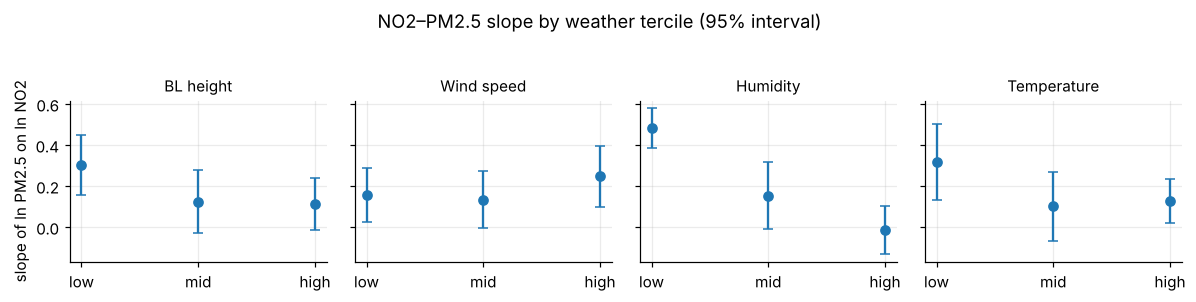

In [15]:
# Slope of ln PM2.5 on ln NO2 within terciles of each weather variable (with calendar controls, HAC errors)
rows = []
for k, nm in (("lnblh_l1", "BL height"), ("lnws_l1", "Wind speed"), ("relative_humidity_2m_l1", "Humidity"), ("temperature_2m_l1", "Temperature")):
    t = pd.qcut(Zd[k], 3, labels=["low", "mid", "high"])
    for lv in ("low", "mid", "high"):
        idx = t == lv; d = Zd[idx]; cd = cal[idx]; cd = cd.loc[:, cd.std() > 0]; Xs = sm.add_constant(pd.concat([d[["lnno2_l1"]], cd], axis=1)); r = sm.OLS(d.lnpm, Xs).fit(cov_type="HAC", cov_kwds=dict(maxlags=24))
        rows.append((nm, lv, r.params["lnno2_l1"], r.conf_int().loc["lnno2_l1", 0], r.conf_int().loc["lnno2_l1", 1], int(idx.sum())))
sl = pd.DataFrame(rows, columns=["moderator", "tercile", "slope", "lo", "hi", "n"]); print(sl.round(2).to_string(index=False))
fig, ax = plt.subplots(1, 4, figsize=(11, 2.6), sharey=True)
for a, (nm, d) in zip(ax, sl.groupby("moderator", sort=False)): a.errorbar(range(3), d.slope, yerr=[d.slope - d.lo, d.hi - d.slope], fmt="o", capsize=3, color="tab:blue"); a.set_xticks(range(3)); a.set_xticklabels(["low", "mid", "high"]); a.set_title(nm, fontsize=10)
ax[0].set_ylabel("slope of ln PM2.5 on ln NO2"); plt.suptitle("NO2–PM2.5 slope by weather tercile (95% interval)", y=1.04); plt.tight_layout(); plt.show()

> **Observation:** The NO2–PM2.5 slope depends on humidity and, less clearly, on BLH. In dry air (lowest humidity tercile) the slope of ln PM2.5 on ln NO2 is 0.48 (95% interval 0.39–0.58), in medium humidity 0.15, and in the most humid tercile −0.02 (−0.13 to 0.10), so the link is strong in dry months and disappears in the monsoon. When BLH is low the slope is 0.30 (0.15–0.45), against 0.12 and 0.11 for mid and high BLH, a pattern consistent with trapped emissions but with overlapping intervals. Wind speed does not show the stagnation pattern (0.16, 0.13, 0.25 from low to high wind), and the temperature pattern is 0.32, 0.10, 0.13. The humidity terciles are partly season, even though calendar controls are included.

## 8. Summary and conclusions

### Key results
- **The calendar explains half of PM2.5.** Month and hour of day alone give R² = 0.50 for ln PM2.5. The highest PM2.5 is in April–May and the lowest in July–August.
- **Many raw weather links are seasonal.** Humidity, pressure and rain correlate strongly with PM2.5 in the raw series (ρ = −0.56, +0.33, −0.36), but after removing month-hour averages the pressure link vanishes (−0.02) and humidity and rain weaken (−0.24, −0.14).
- **Associations that survive the calendar controls:** a deeper boundary layer goes with lower PM2.5 (−16% per SD), warmer-than-usual air with higher (+14% per SD), NO2 with higher (+12% per SD) and rain in the previous hour with lower (−8%). Wind speed has no measurable effect on its own.
- **Weather adds about 6 percentage points of R² beyond the calendar,** and NO2 about 2.5. Granger tests find NO2, BLH, wind speed, pressure and temperature useful for prediction but each adds at most 1.3% of variance, because PM2.5's own past dominates.
- **Rain gives a short dip,** about 10–15% for two hours after onset, estimated from 22 events.
- **The NO2 link depends on the weather:** strong in dry air (slope 0.48) and absent in humid air (−0.02), and stronger with a shallow boundary layer (0.30 against about 0.11).

### Limitations
- Weather ends on 31 Aug, so September–November, the most polluted months, are not covered and the conclusions apply to March–August only.
- One monitoring station; Open-Meteo values are modelled for a grid cell and not measured at the station.
- PM2.5 is missing in 12% of hours; lag and Granger analyses use only gap-free blocks.
- Everything is observational: coefficients describe association, and collinearity between temperature and BLH makes their individual signs hard to interpret.
- The log-linear regression gives average effects; threshold effects (for example very low BLH combined with calm wind) may be missed because those combinations are rare (103 hours in the shallowest, windiest cell).
- Several tests are run; only the Granger tests are corrected for multiple comparisons.
